In [1]:
# load the hypergraph用来统计去噪前后的多个指标
import yaml
import logging
import itertools
import os
import sys
import random

from scipy import sparse
import numpy as np
import seaborn as sns
import networkx as nx
import community

import torch
import torch.nn.functional as F
from torch_geometric.nn import GCNConv, SAGEConv
from torch_geometric.data import Data

from cell.utils import link_prediction_performance
from cell.cell import Cell, EdgeOverlapCriterion, LinkPredictionCriterion
from cell.graph_statistics import compute_graph_statistics

from utils import load_graphs
from cliques_utils import compute_cliques

In [3]:
import logging
import yaml
logging.basicConfig(level=logging.INFO)
logger = logging.getLogger()
logger.setLevel(logging.INFO)
# #dug
# import os
#
# for root, dirs, files in os.walk(os.getcwd()):
#     if "contact-primary-school" in dirs:
#         print("✅ 找到路径:", os.path.join(root, "contact-primary-school"))
# ###################
print("当前工作目录:", os.getcwd())
# print("目录下文件:", os.listdir("data/contact-primary-school"))
config  = yaml.safe_load(open('./config.yml'))
dataset_name = config.get('dataset')  # 取出配置里的数据集名称
target_dir = f"./data/{dataset_name}"
print("目录下文件:", os.listdir(target_dir))
# config['dataset'] = 'NDC-classes'
graphs = load_graphs(config, logger)
config['beta'] = len(graphs['simplicies_train']) * 10

cliques = compute_cliques(graphs, config, logger)


simp = graphs['simplicies_train']

print("=== 原超图基本信息 ===")
print("节点数:", len({v for s in simp for v in s}))  # 所有超边里出现的节点
print("超边数:", len(simp))
simp = list(graphs['simplicies_train'])
print("\n=== 前 5 条超边 ===")
for i, e in enumerate(simp[:5]):
    print(e)


# data = np.array([len(s) for s in graphs['simplicies_train']])
# hist, bins = np.histogram(data, bins=np.linspace(1, 8, 8))
# sns.displot(data)

当前工作目录: /tmp/pycharm_project_479
目录下文件: ['NDC-classes-simplices.txt', 'train.txt', 'test.txt', 'NDC-classes-nverts.txt', 'rho.pkl', 'cliques_train.pkl', 'NDC-classes-times.txt']
number of simplices: 49724
number of unique simplices: 1088
Node index should begin with 0, reindexing the hypergraphs ...
number of nodes in construct graph 1161


INFO:root:Finish loading graphs.
INFO:root:Nodes train: 1161
INFO:root:Simplicies train: 1088
INFO:root:Start computing cliques
INFO:root:Found cache for max cliques train
INFO:root:Number of maximum cliques:624
INFO:root:Optimizing clique sampler .. 
INFO:root:Found cache for rho.
INFO:root:[(16, 16), (2, 2), (1, 1), (3, 3), (4, 4), (13, 13), (5, 5), (7, 7), (6, 6), (19, 19), (15, 15), (9, 9), (18, 18), (14, 14), (8, 8), (11, 11), (21, 21), (10, 10), (12, 12), (4, 2), (23, 23), (3, 2), (9, 1), (16, 1), (6, 4), (3, 1), (5, 3), (5, 2), (18, 1), (6, 2), (2, 1), (6, 5), (15, 14), (4, 3), (19, 1), (5, 4), (7, 6), (7, 5), (8, 6), (7, 3), (7, 1), (9, 2), (11, 9), (20, 19), (8, 7), (8, 2), (7, 4)]
INFO:root:Optimize Clique Sampler: #hyperedges collected:715, recall: 0.6571691176470589, efficiency:0.06571691176470588
INFO:root:Clique analysis done.


number of simplices: 49724
number of unique simplices: 1088
Node index should begin with 0, reindexing the hypergraphs ...
number of nodes in construct graph 1161
Number of maximum cliques: 624
(0, 0), (1, 1), (165, 165), (177, 177), (243, 242), (311, 306), (320, 314), (380, 364), (415, 389), (458, 419), (461, 421), (464, 423), (471, 427), (473, 428), (485, 434), (510, 446), (519, 449), (526, 451), (540, 455), (559, 460), (967, 507), (976, 508), (1174, 522), (1237, 526), (1253, 527), (1898, 554), (2096, 562), (2696, 582), (3296, 601), (3332, 602), (3977, 618), (4305, 626), (4563, 632), (4608, 633), (4880, 638), (4937, 639), (5237, 644), (5482, 648), (6217, 660), (6917, 671), (8142, 687), (8387, 690), (8639, 693), (9134, 698), (9234, 699), (9434, 701), (10134, 708), 
=== 原超图基本信息 ===
节点数: 1161
超边数: 1088

=== 前 5 条超边 ===
(444, 445)
(40, 766, 767)
(377, 378, 379, 380, 381, 382, 383, 384, 385, 386)
(898, 899)
(103, 104, 105, 932, 933)


In [4]:
import torch
import numpy as np
import networkx as nx
import torch.nn as nn
import torch.optim as optim
from torch_geometric.nn import HypergraphConv
import argparse
import torch
import numpy as np
import random



def get_args():
    parser = argparse.ArgumentParser(description="Hypergraph Flow Matching Model")

    # =========================
    # Config / Dataset
    # =========================
    parser.add_argument('--config', type=str, default='./config.yml')
    parser.add_argument('--dataset', type=str, default=None,
                        help='override dataset in config.yml')

    # =========================
    # Training
    # =========================
    parser.add_argument('--num_epochs', type=int, default=400)
    parser.add_argument('--lr', type=float, default=1e-3)
    parser.add_argument('--device', type=str, default='cuda')

    # =========================
    # Flow Matching
    # =========================
    parser.add_argument('--n_steps', type=int, default=20)
    parser.add_argument('--dt', type=float, default=0.05)
    parser.add_argument('--noise_scale', type=float, default=0.2)
    parser.add_argument('--sigma_base', type=float, default=0.2)

    # =========================
    # Spectral Encoder
    # =========================
    parser.add_argument('--k_low', type=int, default=16)
    parser.add_argument('--k_high', type=int, default=16)

    # =========================
    # Peierls Phase
    # =========================
    parser.add_argument('--phi_mode', type=str, default='learnable',
                        choices=['learnable', 'random', 'peierls_structured'])
    parser.add_argument('--phi_scale', type=float, default=0.1)

    # =========================
    # Loss
    # =========================
    parser.add_argument('--lambda_amp', type=float, default=1.0)

    # =========================
    # Sampling
    # =========================
    parser.add_argument('--sample_size', type=int, default=None)

    # =========================
    # Seed
    # =========================
    parser.add_argument('--seed', type=int, default=42)

    return parser.parse_args()

args = get_args()
torch.manual_seed(args.seed)
np.random.seed(args.seed)
random.seed(args.seed)

graph_adjacency_matrix, weighted_graph_adjacency_matrix = nx.to_numpy_array(graphs['G_train'], nodelist=sorted(graphs['G_train'].nodes())), nx.to_numpy_array(graphs['G_weighted'], nodelist=sorted(graphs['G_train'].nodes()))   #构造 adjacency 矩阵

edge_index = torch.tensor(np.array(graph_adjacency_matrix.nonzero()), dtype=torch.long)  #构造 edge_index
data = Data(edge_index=edge_index)
device = 'cuda' if torch.cuda.is_available() else 'cpu'


n = len(graphs['G_train'].nodes())
hyperedges = graphs['simplicies_train']
m = len(hyperedges)


C = torch.zeros((n, m), dtype=torch.cfloat, device=device)
for col, hyperedge in enumerate(hyperedges):
    C[hyperedge, col] = 1.0


def peierls_magnetize(C, phi_mode='learnable', phi_scale=0.1, pos_nodes=None, pos_edges=None, learnable_theta=None):
    n, m = C.shape
    device = C.device
    aux = {}

    if phi_mode == 'random':
        phi = torch.randn(n, m, device=device) * phi_scale
        C_mag = C * torch.exp(1j * phi)
        return C_mag, aux

    if phi_mode == 'peierls_structured':
        if pos_nodes is None or pos_edges is None:
            raise ValueError("pos_nodes and pos_edges required for structured Peierls")
        r_nodes = torch.tensor(pos_nodes, dtype=torch.float32, device=device)  # (n,d)
        r_edges = torch.tensor(pos_edges, dtype=torch.float32, device=device)  # (m,d)
        diff = r_nodes[:, None, :] - r_edges[None, :, :]  # (n,m,d)
        proj = diff[..., 0]  #
        phi = phi_scale * proj
        C_mag = C * torch.exp(1j * phi)
        return C_mag, aux

    if phi_mode == 'learnable':
        if learnable_theta is None:
            torch.manual_seed(0)
            theta = torch.nn.Parameter(torch.randn(n + m, device=device) * (phi_scale*0.5))
            aux['theta_param'] = theta
        else:
            theta = learnable_theta.to(device)
            aux['theta_param'] = theta

        theta_nodes = theta[:n].view(n,1)
        theta_edges = theta[n:].view(1,m)
        phi = theta_nodes - theta_edges
        C_mag = C * torch.exp(1j * phi)
        return C_mag, aux

    raise ValueError("unknown phi_mode")


def build_block_hermitian(C_mag):
    n, m = C_mag.shape
    H = torch.zeros((n+m, n+m), dtype=torch.cfloat, device=C_mag.device)
    H[:n, n:] = C_mag
    H[n:, :n] = C_mag.conj().T
    return H


def spectral_encoder_local_global(H, k_low=16, k_high=16):

    n_nodes = H.shape[0]


    eigvals, eigvecs = torch.linalg.eigh(H)  #


    U_low = eigvecs[:, :k_low]        # (n+m, k_low)
    Lambda_low = eigvals[:k_low]      # (k_low,)
    low_feat = torch.cat([
        Lambda_low.unsqueeze(0).repeat(n_nodes, 1),
        U_low.real,
        U_low.imag
    ], dim=-1)  # shape: (n+m, 3*k_low)


    U_high = eigvecs[:, -k_high:]     # (n+m, k_high)
    Lambda_high = eigvals[-k_high:]   # (k_high,)
    high_feat = torch.cat([
        Lambda_high.unsqueeze(0).repeat(n_nodes, 1),
        U_high.real,
        U_high.imag
    ], dim=-1)  # shape: (n+m, 3*k_high)


    Z0 = torch.cat([low_feat, high_feat], dim=-1)  # (n+m, 3*k_low + 3*k_high)

    return Z0

# ---------- helper: convert biadjacency -> hyperedge_index, hyperedge_weight ----------
def bi_to_hyperedge_index(C, eps=1e-8):
    """
    C: (n, m) dense biadjacency (can be real or complex). Nonzero -> incidence.
    returns: hyperedge_index (2, E) long, hyperedge_weight (m,) float
    """
    device = C.device
    # mask nonzero (work with complex as well)
    mask = (torch.abs(C) > eps)
    rows, cols = mask.nonzero(as_tuple=True)   # node idx, hyperedge idx
    if rows.numel() == 0:
        return torch.empty((2,0), dtype=torch.long, device=device), torch.ones((C.size(1),), dtype=torch.float32, device=device)
    he_idx = torch.stack([rows.long(), cols.long()], dim=0)  # (2, E)
    he_w = torch.ones((C.size(1),), dtype=torch.float32, device=device)  # per-hyperedge weight
    return he_idx, he_w

# ---------- patched VectorFieldHGNN ----------

class VectorFieldHGNN(nn.Module):
    def __init__(self, latent_dim):
        super().__init__()
        self.latent_dim = latent_dim
        hidden_dim = 128  # conv1

        # Time embedding
        self.time_embed = nn.Sequential(
            nn.Linear(1, 64),
            nn.SiLU(),
            nn.Linear(64, 64)
        )

        # Projection of time embedding to match layer dims
        self.proj_t1 = nn.Linear(64, hidden_dim)      # for conv1 (128)
        self.proj_t2 = nn.Linear(64, latent_dim)      # for conv2 (latent_dim)

        # C_feat encoder (maps (real,imag) -> latent_dim per entry)
        self.C_encoder = nn.Sequential(
            nn.Linear(2, 32),
            nn.SiLU(),
            nn.Linear(32, latent_dim)
        )

        # Projection of C_global to match layer dims
        self.proj_C1 = nn.Linear(latent_dim, hidden_dim)   # for conv1
        self.proj_C2 = nn.Linear(latent_dim, latent_dim)   # for conv2

        # HGNN layers
        self.conv1 = HypergraphConv(latent_dim, hidden_dim)
        self.conv2 = HypergraphConv(hidden_dim, latent_dim)

    def forward(self, z, hyperedge_index, t, hyperedge_weight=None, C_feat=None):
        device = z.device
        N = z.shape[0]


        t = t.reshape(-1, 1).to(device)      # (N, 1)
        t_emb = self.time_embed(t)           # (N, 64)
        time_shift1 = self.proj_t1(t_emb)    # (N, hidden_dim)
        time_shift2 = self.proj_t2(t_emb)    # (N, latent_dim)


        if C_feat is not None:
            # want C_feat = (n, m, 2). Allow (m,n,2) -> transpose
            if C_feat.shape[0] != N and C_feat.shape[1] == N:
                C_feat = C_feat.transpose(0, 1)   # (n,m,2)

            # encode per-entry
            # C_lat: (n, m, latent_dim)
            C_lat = self.C_encoder(C_feat)

            # pool to global: mean over node & hyperedge dims -> (latent_dim,)
            C_global = C_lat.mean(dim=(0, 1))    # (latent_dim,)
            C_global = C_global.unsqueeze(0)     # (1, latent_dim)
            # project to match each layer, then expand to (N, dim)
            C_global1 = self.proj_C1(C_global).expand(N, -1)   # (N, hidden_dim)
            C_global2 = self.proj_C2(C_global).expand(N, -1)   # (N, latent_dim)
        else:
            # zeros with correct shape
            C_global1 = torch.zeros((N, time_shift1.shape[1]), device=device)
            C_global2 = torch.zeros((N, time_shift2.shape[1]), device=device)


        if hyperedge_weight is not None:
            x = self.conv1(z, hyperedge_index, hyperedge_weight)
        else:
            x = self.conv1(z, hyperedge_index)

        x = F.relu(x)
        # add projected time and global condition (same dim as x)
        x = x + time_shift1 + C_global1


        if hyperedge_weight is not None:
            x = self.conv2(x, hyperedge_index, hyperedge_weight)
        else:
            x = self.conv2(x, hyperedge_index)

        # add projected time and global condition for layer2
        x = x + time_shift2 + C_global2

        return x


class CFM(nn.Module):
    def __init__(self, vector_field, n_steps=20, dt=0.05, noise_scale=1.0):
        super().__init__()
        self.vector_field = vector_field
        self.n_steps = n_steps
        self.dt = dt
        self.noise_scale = noise_scale

    def forward(self, z0, z1, C, C_feat=None,
                return_trajectory=False, training=False, noise_scale_override=None):
        """
        z0: (N,D)
        z1: unused here (保留接口)
        C: biadjacency or hyperedge index
        C_feat: (n,m,2) real+imag features
        """

        # clone initial point
        z = z0.clone()
        traj = [z.clone()] if return_trajectory else None

        # -------------------------------
        # Prepare hyperedge index / weight
        # -------------------------------
        if isinstance(C, torch.Tensor) and C.dtype in (torch.int64, torch.long) and C.size(0) == 2:
            hyperedge_index = C.to(z.device).long()
            hyperedge_weight = None
        else:
            he_idx, he_w = bi_to_hyperedge_index(C)
            hyperedge_index = he_idx.to(z.device).long()
            hyperedge_weight = he_w.to(z.device).float()

        # noise schedule
        noise_scale_use = self.noise_scale if noise_scale_override is None else noise_scale_override

        # -------------------------------
        # Integrate the flow
        # -------------------------------
        for i in range(self.n_steps):

            t = (i / max(1, self.n_steps)) * torch.ones(z.size(0), 1, device=z.device)

            pred_v = self.vector_field(
                z,
                hyperedge_index,
                t,
                hyperedge_weight=hyperedge_weight,
                C_feat=C_feat
            )

            # noise
            if training:
                noise = torch.randn_like(z) * (noise_scale_use * (self.dt**0.5))
            else:
                noise = (torch.randn_like(z) * (noise_scale_use * (self.dt**0.5))
                         if noise_scale_use > 0 else torch.zeros_like(z))

            z = z + self.dt * pred_v + noise

            if return_trajectory:
                traj.append(z.clone())

        return (z, traj) if return_trajectory else z


def spectral_decoder(Z, n, m, k_low=16, k_high=16):
    n_total = n + m
    idx = 0

    # 低频
    Lambda_low = Z[:, idx:idx+k_low]; idx += k_low
    U_low_real = Z[:, idx:idx+k_low]; idx += k_low
    U_low_imag = Z[:, idx:idx+k_low]; idx += k_low
    U_low = U_low_real + 1j * U_low_imag

    # 高频
    Lambda_high = Z[:, idx:idx+k_high]; idx += k_high
    U_high_real = Z[:, idx:idx+k_high]; idx += k_high
    U_high_imag = Z[:, idx:idx+k_high]; idx += k_high
    U_high = U_high_real + 1j * U_high_imag

    U_all = torch.cat([U_low, U_high], dim=-1)          # (n+m, k_low+k_high)
    # 将 Lambda 转成复数，shape = (k_low+k_high,)
    Lambda_all = torch.cat([Lambda_low.mean(dim=0), Lambda_high.mean(dim=0)], dim=0).to(torch.cfloat)

    H_gen = U_all @ torch.diag(Lambda_all) @ U_all.conj().T
    return H_gen


class EdgeDecoder(nn.Module):
    def __init__(self, latent_dim):
        super().__init__()
        self.net_amp = nn.Sequential(
            nn.Linear(latent_dim, 64),
            nn.ReLU(),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Linear(32, 1),
            nn.Sigmoid()   # <-- 改为 Sigmoid，输出 (0,1)
        )
        self.net_phase = nn.Sequential(
            nn.Linear(latent_dim, 32),
            nn.ReLU(),
            nn.Linear(32, 1)
        )

    def forward(self, edge_emb):
        amp = self.net_amp(edge_emb).squeeze(-1)    # (m,) in (0,1)
        phase = self.net_phase(edge_emb).squeeze(-1)
        return amp, phase



C_mag, aux = peierls_magnetize(
    C,
    phi_mode=args.phi_mode,
    phi_scale=args.phi_scale
)

H = build_block_hermitian(C_mag)
C_mag_target, aux_target = peierls_magnetize(C,phi_mode='learnable',phi_scale=0.1)

H_target = build_block_hermitian(C_mag_target)

Z1 = spectral_encoder_local_global(
    H_target,
    k_low=args.k_low,
    k_high=args.k_high
).to(device)

noise_scale = args.noise_scale
Z0 = noise_scale * torch.randn_like(Z1)
latent_dim = Z0.shape[1]
n_nodes = C.real.shape[0]
n_edges = C.real.shape[1]

C_feat = torch.stack([C_mag.real, C_mag.imag], dim=-1)

he_idx, he_w = bi_to_hyperedge_index(C_mag)
he_idx = he_idx.to(device).long().detach()
he_w = he_w.to(device).float().detach()

Z0 = Z0.clone().detach().to(device)
Z1 = Z1.clone().detach().to(device)
C_feat = C_feat.clone().detach().to(device)

cfm = CFM(
    VectorFieldHGNN(latent_dim),
    n_steps=args.n_steps,
    dt=args.dt,
    noise_scale=args.noise_scale
).to(device)

optimizer = optim.Adam(list(cfm.vector_field.parameters()), lr=args.lr)


num_epochs = args.num_epochs
sigma_base = args.sigma_base

for epoch in range(num_epochs):

    optimizer.zero_grad()

    # sample t
    t_scalar = float(torch.rand(1).item())
    t = t_scalar * torch.ones(Z0.size(0), 1, device=device)

    # sample noisy interpolation
    eps = torch.randn_like(Z0, device=device)
    z_t = (1 - t_scalar) * Z0 + t_scalar * Z1 + sigma_base * (t_scalar**0.5) * eps
    z_t.requires_grad_(True)

    # ----- key part: pass C_feat -----
    pred_v = cfm.vector_field(z_t, he_idx, t, he_w, C_feat)

    denom = max(1e-6, 1.0 - t_scalar)
    target_v = (Z1 - z_t) / denom
    target_v = target_v.detach()

    loss = F.mse_loss(pred_v, target_v)

    loss.backward()
    optimizer.step()

    if (epoch + 1) % 20 == 0:
        print(f"Epoch {epoch+1}/{num_epochs}, loss={loss.item():.6f}")

#-------------------------------------------训练Z0-Z1的向量场完毕--------------------------------------------------
edge_decoder = EdgeDecoder(latent_dim).to(device)

graph_adjacency_matrix, weighted_graph_adjacency_matrix = nx.to_numpy_array(graphs['G_train'], nodelist=sorted(graphs['G_train'].nodes())), nx.to_numpy_array(graphs['G_weighted'], nodelist=sorted(graphs['G_train'].nodes()))
edge_index = torch.tensor(np.array(graph_adjacency_matrix.nonzero()), dtype=torch.long).to(device)
edge_value = torch.tensor(weighted_graph_adjacency_matrix[graph_adjacency_matrix.nonzero()],dtype=torch.float).to(device)
A_tensor = edge_value.clone().detach().to(device).float()  # (m,)
A_np = A_tensor.cpu().numpy()

A_min, A_max = A_np.min(), A_np.max()

A_tensor = edge_value.clone().detach().to(device).float()  # (m,)
A_np = A_tensor.cpu().numpy()
A_min, A_max = float(A_np.min()), float(A_np.max())


if (A_max - A_min) < 1e-8:
    A_min, A_max = 0.0, 1.0


A_edge_list = [
    weighted_graph_adjacency_matrix[np.ix_(he, he)].mean()
    for he in hyperedges
]
A_edge = torch.tensor(A_edge_list, dtype=torch.float32, device=device)  # (n_edges,)


A_edge_norm = (A_edge - A_min) / (A_max - A_min + 1e-12)
A_edge_norm = A_edge_norm.clamp(0.0, 1.0)

optimizer = optim.Adam(
    list(cfm.vector_field.parameters()) + list(edge_decoder.parameters()),
    lr=args.lr
)

lambda_amp = 1.0
for epoch in range(num_epochs):
    optimizer.zero_grad()

    t_scalar = float(torch.rand(1).item())
    t = t_scalar * torch.ones(Z0.size(0), 1, device=device)

    eps = torch.randn_like(Z0, device=device)
    z_t = (1.0 - t_scalar) * Z0 + t_scalar * Z1 + sigma_base * (t_scalar ** 0.5) * eps
    z_t = z_t.detach()
    z_t.requires_grad_(True)

    pred_v = cfm.vector_field(z_t, he_idx, t, he_w)
    denom = max(1e-6, 1.0 - t_scalar)
    target_v = ((Z1 - z_t) / denom).detach()

    loss_flow = F.mse_loss(pred_v, target_v)

    # 使用 Z1 的 hyperedge embedding 做 amplitude supervision
    Z1_edges = Z1[n_nodes:n_nodes + n_edges, :]        # (n_edges, latent_dim)
    amp_pred, _ = edge_decoder(Z1_edges)               # amp_pred ∈ (0,1)

    # 线性 MSE between normalized true amp and predicted amp
    loss_amp = F.mse_loss(amp_pred, A_edge_norm)  #损失

    loss = loss_flow + lambda_amp * loss_amp
    loss.backward()
    optimizer.step()

    if (epoch + 1) % 20 == 0:
        # debug prints
        with torch.no_grad():
            print(f"Epoch {epoch+1}/{num_epochs}, loss_flow={loss_flow.item():.6f}, loss_amp={loss_amp.item():.6f}")
            print(f"  amp_pred stats (min, mean, max): {float(amp_pred.min()):.4f}, {float(amp_pred.mean()):.4f}, {float(amp_pred.max()):.4f}")
            print(f"  A_edge_norm stats (min, mean, max): {float(A_edge_norm.min()):.4f}, {float(A_edge_norm.mean()):.4f}, {float(A_edge_norm.max()):.4f}")
            # print("第0条超边:", list(hyperedges)[0],"A_edge_norm[0]:", float(A_edge_norm[0]))


n_edges_target = len(graphs['simplicies_train'])  # 或 2000
z0_sample = torch.randn(n_nodes + n_edges_target, latent_dim, device=device)

with torch.no_grad():
    Z_gen = cfm(z0_sample, Z1, C.real)  # (n+m, latent_dim)

# ------------------ decode ------------------
edge_emb_gen = Z_gen[n_nodes:n_nodes + n_edges_target, :]
edge_amp_gen, edge_phase_gen = edge_decoder(edge_emb_gen)

H_gen = spectral_decoder(Z_gen, n_nodes, n_edges_target)
C_mag_gen = H_gen[:n_nodes, n_nodes:]

C_gen_prob_raw = C_mag_gen.abs()  # (n, m), >=0


col_max = C_gen_prob_raw.max(dim=0, keepdim=True).values  # shape (1, m)
col_max = col_max.clamp(min=1e-8)
C_gen_prob_raw_norm = C_gen_prob_raw / col_max


edge_amp_scaled = edge_amp_gen * (A_max - A_min) + A_min  # (m,)
edge_amp_int = torch.round(edge_amp_scaled).long()
edge_amp_int = edge_amp_int.to(C_gen_prob_raw_norm.device).unsqueeze(0)  # (1,m)


C_gen_prob = C_gen_prob_raw_norm * edge_amp_int.float()  # (n,m)

C_gen_binary = (C_gen_prob > 0.2).float()


generated_hyperedges = []
for e in range(n_edges):
    nodes = torch.where(C_gen_binary[:, e] > 0.5)[0].tolist()
    generated_hyperedges.append(nodes)


edge_weights = edge_amp_int.squeeze(0).cpu().numpy()  #
B = np.array(edge_weights, dtype=int)

generated_hyperedges = []
edge_weights = []

for e in range(n_edges_target):

    nodes = torch.where(C_gen_binary[:, e] > 0.5)[0].tolist()
    generated_hyperedges.append(nodes)
    w = max(len(nodes), 1)
    edge_weights.append(w)

B = np.array(B,dtype=int)


C_orig_binary = (C.abs() > 0).float()

num_orig_edges = int(C_orig_binary.sum().item())
num_gen_edges = int(C_gen_binary.sum().item())


# matched_edges = int((C_gen_binary * C_orig_binary).sum().item())
#
# missing_edges = int(((C_orig_binary == 1) & (C_gen_binary == 0)).sum().item())
#
# extra_edges = int(((C_orig_binary == 0) & (C_gen_binary == 1)).sum().item())


C_gen_prob_weighted = C_gen_prob.clone()  # (n_nodes, n_edges_target)
n_nodes, n_edges_target = C_gen_prob_weighted.shape
C_test_binary_final = C_gen_prob_weighted.clone()


def denoise_hypergraph_cuda(C_gen: torch.Tensor, C_orig: torch.Tensor) -> torch.Tensor:
    """
    Structure-aware denoising on GPU (CUDA).
    Removes edges in C_gen that are not in C_orig.

    Args:
        C_gen: (n_nodes, n_edges) float tensor, generated binary incidence (0/1 or probabilities)
        C_orig: (n_nodes, n_edges) float tensor, original hypergraph incidence (0/1)

    Returns:
        C_denoised: (n_nodes, n_edges) float tensor, denoised version of C_gen
    """
    assert C_gen.shape == C_orig.shape, "Generated and original incidence must have same shape."

    # Ensure both on same device (GPU)
    device = C_gen.device
    C_orig = C_orig.to(device)

    # Clone to avoid modifying original
    C_denoised = C_gen.clone()

    n_edges = C_gen.shape[1]


    for e in range(n_edges):

        gen_nodes = torch.nonzero(C_denoised[:, e] > 0.0, as_tuple=False).squeeze(-1)
        if gen_nodes.numel() == 0:
            continue

        orig_nodes = torch.nonzero(C_orig[:, e] > 0.0, as_tuple=False).squeeze(-1)
        if orig_nodes.numel() == 0:

            C_denoised[:, e] = 0.0
            continue

        gen_set = set(gen_nodes.tolist())
        orig_set = set(orig_nodes.tolist())
        keep_nodes = list(gen_set & orig_set)


        C_denoised[:, e] = 0.0
        if keep_nodes:
            keep_tensor = torch.tensor(keep_nodes, device=device)
            C_denoised[keep_tensor, e] = 1.0

    return C_denoised



B_test = edge_amp_int.squeeze(0).cpu().numpy()


num_gen_edges_test = int(C_test_binary_final.sum().item())

C_test_binary_final = (C_test_binary_final != 0).float()

C_test_binary_final = denoise_hypergraph_cuda(C_test_binary_final, C_orig_binary)



matched_edges_test = int((C_test_binary_final * C_orig_binary).sum().item())
missing_edges_test = int(((C_orig_binary == 1) & (C_test_binary_final == 0)).sum().item())
extra_edges_test = int(((C_orig_binary == 0) & (C_test_binary_final == 1)).sum().item())


C_test_binary_final_01 = (C_test_binary_final != 0).float()
recall    = matched_edges_test / (matched_edges_test + missing_edges_test)
precision = matched_edges_test / (matched_edges_test + extra_edges_test)
f1_score  = 2 * (precision * recall) / (precision + recall) if (precision + recall) > 0 else 0

print("matched:", matched_edges_test)
print("missing:", missing_edges_test)
print("extra:", extra_edges_test)
print("Recall:", recall)
print("Precision:", precision)
print("F1-score:", f1_score)


def columns_to_hyperedges(C):
    _, M = C.shape
    hyperedges = []
    for j in range(M):
        nodes = torch.where(C[:, j] != 0)[0].tolist()
        hyperedges.append(nodes)
    return hyperedges

orig_edges = columns_to_hyperedges(C_orig_binary)
gen_edges = columns_to_hyperedges(C_test_binary_final_01)

matched_count = sum(1 for o, g in zip(orig_edges, gen_edges) if set(o) == set(g))
missing_count = len(orig_edges) - matched_count
extra_count = len(gen_edges) - matched_count

print(matched_count, missing_count, extra_count)




Epoch 20/400, loss=40.313221
Epoch 40/400, loss=25.434835
Epoch 60/400, loss=16.166708
Epoch 80/400, loss=7.486452
Epoch 100/400, loss=4.109358
Epoch 120/400, loss=2.049814
Epoch 140/400, loss=1.202251
Epoch 160/400, loss=0.507339
Epoch 180/400, loss=4.586975
Epoch 200/400, loss=0.125353
Epoch 220/400, loss=0.110979
Epoch 240/400, loss=0.132715
Epoch 260/400, loss=2.371194
Epoch 280/400, loss=0.195132
Epoch 300/400, loss=0.066543
Epoch 320/400, loss=0.073938
Epoch 340/400, loss=0.897221
Epoch 360/400, loss=0.098084
Epoch 380/400, loss=0.053786
Epoch 400/400, loss=0.098361
Epoch 20/400, loss_flow=1.444619, loss_amp=0.009623
  amp_pred stats (min, mean, max): 0.0270, 0.0273, 0.0274
  A_edge_norm stats (min, mean, max): 0.0000, 0.0564, 0.4432
Epoch 40/400, loss_flow=0.407348, loss_amp=0.009957
  amp_pred stats (min, mean, max): 0.0218, 0.0220, 0.0221
  A_edge_norm stats (min, mean, max): 0.0000, 0.0564, 0.4432
Epoch 60/400, loss_flow=0.742287, loss_amp=0.009203
  amp_pred stats (min, mean

INFO:root:Hyperedges source: /tmp/pycharm_project_479/data/contact-primary-school/test.txt
INFO:root:Loaded 106879 hyperedges.
INFO:root:构造 incidence matrix …
INFO:root:Nodes: 242, Hyperedges: 106879
INFO:root:构造 bipartite adjacency …
INFO:root:计算 top-21 谱 …


Saved spectrum figure as /tmp/pycharm_project_479/photo/contact_high_school_spectrum_root.svg


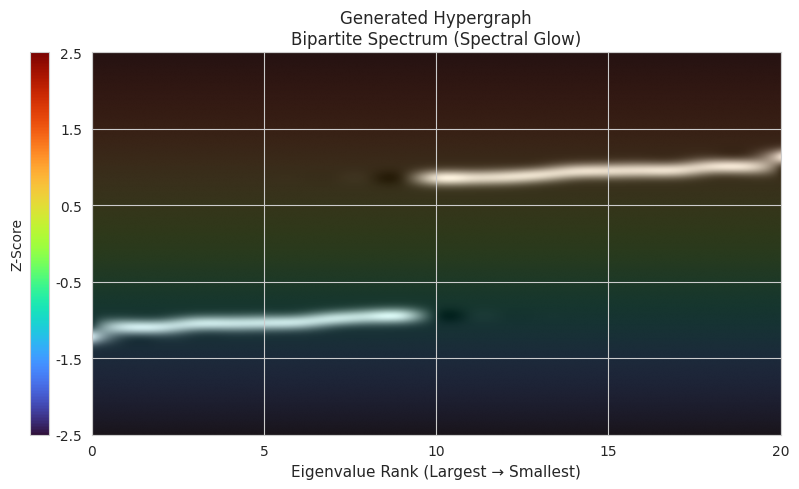

In [7]:

#原超图和超图生成的对比实验
import numpy as np
import matplotlib.pyplot as plt
from scipy.sparse import coo_matrix, bmat
from scipy.sparse.linalg import eigsh
from pathlib import Path
import logging
import os
# =========================
# Logging
# =========================
logger = logging.getLogger()
if logger.hasHandlers():
    logger.handlers.clear()
logging.basicConfig(level=logging.INFO)
logger.setLevel(logging.INFO)

# =========================
# 只需改这几行就能切换数据
# =========================
# 直接填文件所在目录和文件名
data_dir = Path("data/contact-primary-school")  # 文件所在目录
data_file = "test.txt"                        # 文件名

# =========================
# 自动生成路径
# =========================
data_path = data_dir / data_file
if not data_path.exists():
    raise FileNotFoundError(f"没有找到文件: {data_path.resolve()}")

logger.info("Hyperedges source: %s", data_path.resolve())

# =========================
# 加载 hyperedges
# =========================
hyperedges_gen = []
with data_path.open("r") as f:
    for line in f:
        if line.strip():
            hyperedges_gen.append(list(map(int, line.split())))

hg = hyperedges_gen
logger.info(f"Loaded {len(hg)} hyperedges.")

# =========================
# Incidence matrix
# =========================
def incidence_sparse(hg):
    nodes = sorted(set(v for e in hg for v in e))
    node_map = {v: i for i, v in enumerate(nodes)}

    rows, cols = [], []
    for e_id, e in enumerate(hg):
        for v in e:
            rows.append(node_map[v])
            cols.append(e_id)

    data = np.ones(len(rows))
    H = coo_matrix((data, (rows, cols)), shape=(len(nodes), len(hg)))
    return H, len(nodes), len(hg)

# =========================
# Bipartite adjacency
# =========================
def bipartite_adjacency(H):
    return bmat([[None, H],
                 [H.T, None]], format="csr")

# =========================
# Top-k spectrum
# =========================
def topk_spectrum(A, k):
    return np.sort(
        eigsh(A, k=k, which="LM", return_eigenvectors=False)
    )
CONFIG = {
    "topk": 21
}
# =========================
# Main
# =========================
k = CONFIG["topk"]

logger.info("构造 incidence matrix …")
H, n, m = incidence_sparse(hg)
logger.info(f"Nodes: {n}, Hyperedges: {m}")

logger.info("构造 bipartite adjacency …")
A = bipartite_adjacency(H)

logger.info(f"计算 top-{k} 谱 …")
eigvals = topk_spectrum(A, k)

# ------------------------------
# 数据预处理（保持原始标准化）
# ------------------------------
eigvals_z = (eigvals - eigvals.mean()) / eigvals.std()
num_ranks = len(eigvals_z)

z_min, z_max = -2.5, 2.5
num_y_bins = 300
z_axis = np.linspace(z_min, z_max, num_y_bins)

# ------------------------------
# Step 1: 横向插值提高分辨率
# ------------------------------
num_ranks_vis = 500  # 横向显示分辨率，比特征值多
background = np.tile(z_axis[:, None], (1, num_ranks_vis))

# Glow 构建
sigma = 0.07
glow_lowres = np.zeros((num_y_bins, num_ranks))
for r, z in enumerate(eigvals_z):
    glow_lowres[:, r] = np.exp(-0.5 * ((z_axis - z) / sigma) ** 2)

# 横向插值
from scipy.interpolate import interp1d
x_orig = np.linspace(0, 1, num_ranks)
x_new = np.linspace(0, 1, num_ranks_vis)
f_interp = interp1d(x_orig, glow_lowres, kind='cubic', axis=1)
glow = f_interp(x_new)
glow /= glow.max()  # 归一化

# ------------------------------
# Step 2: 绘图
# ------------------------------
fig, ax = plt.subplots(figsize=(9, 5))

# 背景
im_bg = ax.imshow(background, origin="lower", aspect="auto",
                  cmap="turbo", vmin=z_min, vmax=z_max,
                  extent=[0, 1, z_min, z_max],
                  interpolation='bicubic')  # ⚡ 使用插值

# Glow
ax.imshow(glow, origin="lower", aspect="auto",
          cmap="gray", alpha=0.85,
          extent=[0, 1, z_min, z_max],
          interpolation='bicubic')  # ⚡ 平滑插值

ax.set_xlabel("Eigenvalue Rank (Largest → Smallest)", fontsize=11)
ax.set_ylabel("Z-Score", fontsize=11)
ax.set_xticks(np.linspace(0, 1, num_ranks)[::5],
              labels=np.arange(0, num_ranks + 1, 5))
ax.set_yticks(np.linspace(z_min, z_max, 6),
              labels=np.round(np.linspace(z_min, z_max, 6), 2))
ax.set_title("Generated Hypergraph\nBipartite Spectrum (Spectral Glow)", fontsize=12)

cbar = plt.colorbar(im_bg, ax=ax, location='left', pad=0.05)
cbar.set_label("Z-Score", fontsize=10)
cbar.set_ticks([])
cbar.ax.tick_params(length=0)

plt.tight_layout()

# ------------------------------



# Step 3: 保存 SVG（向量化 + 白底）
# ------------------------------
save_dir = "/tmp/pycharm_project_479/photo"
os.makedirs(save_dir, exist_ok=True)
output_file = os.path.join(save_dir, "contact_high_school_spectrum_root.svg")

plt.savefig(output_file, format="svg", bbox_inches='tight',
            transparent=False, facecolor='white')  # ⚡ 不透明白底，向量化
print(f"Saved spectrum figure as {output_file}")

# 显示图像
plt.show()

INFO:root:Hyperedges source: /tmp/pycharm_project_479/generate_graphs/TheRA/contact-primary-school/contact_primary_HE_THera.txt
INFO:root:Loaded 12704 hyperedges.
INFO:root:构造 incidence matrix …
INFO:root:Nodes: 242, Hyperedges: 12704
INFO:root:构造 bipartite adjacency …
INFO:root:计算 top-21 谱 …


Saved spectrum figure as /tmp/pycharm_project_479/photo/contact_primary_school_spectrum_TheRA.svg


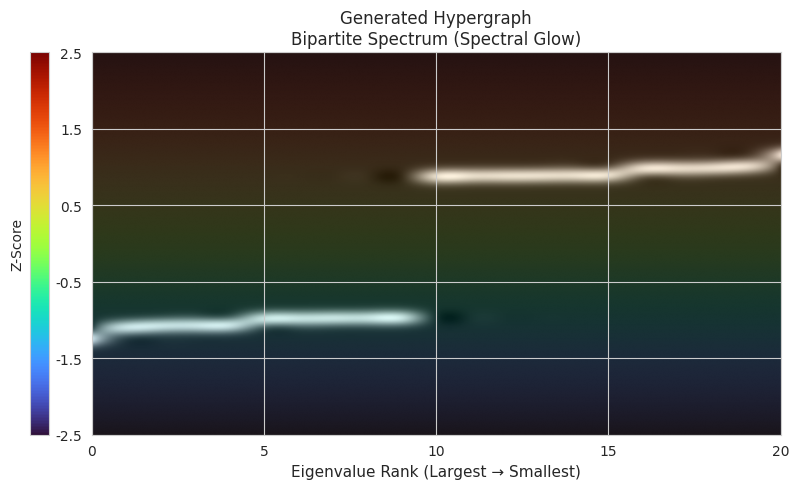

In [78]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.sparse import coo_matrix, bmat
from scipy.sparse.linalg import eigsh
from pathlib import Path
import logging

# =========================
# Logging
# =========================
logger = logging.getLogger()
if logger.hasHandlers():
    logger.handlers.clear()
logging.basicConfig(level=logging.INFO)
logger.setLevel(logging.INFO)

# =========================
# 只需改这几行就能切换数据
# =========================
hypergraph_type = "TheRA"          # 例如 HyperDK11 / HyperDK00 / Hyperlap+
sub_dataset = "contact-primary-school"    # 例如 contact-high-school / email-Eu / NDC-classes
file_index = 3                          # 1,2,3,... 对应 hyperdk-1.txt, hyperdk-2.txt ...

# =========================
# 自动生成路径
# =========================
BASE_DIR = Path("generate_graphs")
search_pattern = f"contact_primary_HE_THera*"
data_path = next(
    BASE_DIR.glob(f"{hypergraph_type}/{sub_dataset}/{search_pattern}"),
    None
)

if data_path is None:
    raise FileNotFoundError(f"没有找到文件: {hypergraph_type}/{sub_dataset}/{search_pattern}")

logger.info("Hyperedges source: %s", data_path.resolve())

# =========================
# 加载 hyperedges
# =========================
hyperedges_gen = []
with data_path.open("r") as f:
    for line in f:
        line = line.strip()
        if line:
            # 把逗号换成空格，再分割
            hyperedges_gen.append(list(map(int, line.replace(",", " ").split())))


hg = hyperedges_gen
logger.info(f"Loaded {len(hg)} hyperedges.")

# =========================
# Incidence matrix
# =========================
def incidence_sparse(hg):
    nodes = sorted(set(v for e in hg for v in e))
    node_map = {v: i for i, v in enumerate(nodes)}

    rows, cols = [], []
    for e_id, e in enumerate(hg):
        for v in e:
            rows.append(node_map[v])
            cols.append(e_id)

    data = np.ones(len(rows))
    H = coo_matrix((data, (rows, cols)), shape=(len(nodes), len(hg)))
    return H, len(nodes), len(hg)

# =========================
# Bipartite adjacency
# =========================
def bipartite_adjacency(H):
    return bmat([[None, H],
                 [H.T, None]], format="csr")

# =========================
# Top-k spectrum
# =========================
def topk_spectrum(A, k):
    return np.sort(
        eigsh(A, k=k, which="LM", return_eigenvectors=False)
    )

CONFIG = {
    "topk": 21
}
# =========================
# Main
# =========================
k = CONFIG["topk"]

logger.info("构造 incidence matrix …")
H, n, m = incidence_sparse(hg)
logger.info(f"Nodes: {n}, Hyperedges: {m}")

logger.info("构造 bipartite adjacency …")
A = bipartite_adjacency(H)

logger.info(f"计算 top-{k} 谱 …")
eigvals = topk_spectrum(A, k)

# ------------------------------
# 数据预处理（保持原始标准化）
# ------------------------------
eigvals_z = (eigvals - eigvals.mean()) / eigvals.std()
num_ranks = len(eigvals_z)

z_min, z_max = -2.5, 2.5
num_y_bins = 300
z_axis = np.linspace(z_min, z_max, num_y_bins)

# ------------------------------
# Step 1: 横向插值提高分辨率
# ------------------------------
num_ranks_vis = 500  # 横向显示分辨率，比特征值多
background = np.tile(z_axis[:, None], (1, num_ranks_vis))

# Glow 构建
sigma = 0.07
glow_lowres = np.zeros((num_y_bins, num_ranks))
for r, z in enumerate(eigvals_z):
    glow_lowres[:, r] = np.exp(-0.5 * ((z_axis - z) / sigma) ** 2)

# 横向插值
from scipy.interpolate import interp1d
x_orig = np.linspace(0, 1, num_ranks)
x_new = np.linspace(0, 1, num_ranks_vis)
f_interp = interp1d(x_orig, glow_lowres, kind='cubic', axis=1)
glow = f_interp(x_new)
glow /= glow.max()  # 归一化

# ------------------------------
# Step 2: 绘图
# ------------------------------
fig, ax = plt.subplots(figsize=(9, 5))

# 背景
im_bg = ax.imshow(background, origin="lower", aspect="auto",
                  cmap="turbo", vmin=z_min, vmax=z_max,
                  extent=[0, 1, z_min, z_max],
                  interpolation='bicubic')  # ⚡ 使用插值

# Glow
ax.imshow(glow, origin="lower", aspect="auto",
          cmap="gray", alpha=0.85,
          extent=[0, 1, z_min, z_max],
          interpolation='bicubic')  # ⚡ 平滑插值

ax.set_xlabel("Eigenvalue Rank (Largest → Smallest)", fontsize=11)
ax.set_ylabel("Z-Score", fontsize=11)
ax.set_xticks(np.linspace(0, 1, num_ranks)[::5],
              labels=np.arange(0, num_ranks + 1, 5))
ax.set_yticks(np.linspace(z_min, z_max, 6),
              labels=np.round(np.linspace(z_min, z_max, 6), 2))
ax.set_title("Generated Hypergraph\nBipartite Spectrum (Spectral Glow)", fontsize=12)

cbar = plt.colorbar(im_bg, ax=ax, location='left', pad=0.05)
cbar.set_label("Z-Score", fontsize=10)
cbar.set_ticks([])
cbar.ax.tick_params(length=0)

plt.tight_layout()

# ------------------------------
# Step 3: 保存 SVG（向量化 + 白底）
# ------------------------------
save_dir = "/tmp/pycharm_project_479/photo"
os.makedirs(save_dir, exist_ok=True)
output_file = os.path.join(save_dir, "contact_primary_school_spectrum_TheRA.svg")

plt.savefig(output_file, format="svg", bbox_inches='tight',
            transparent=False, facecolor='white')  # ⚡ 不透明白底，向量化
print(f"Saved spectrum figure as {output_file}")

# 显示图像
plt.show()



In [10]:
# pickle.dump(metric_baseline, open('./metric_baseline.pkl', 'wb'))